In [34]:
import os, sys, time, json, pickle, warnings, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy import ndimage as ndi
from scipy.signal import fftconvolve
from joblib import Parallel, delayed

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# le notebook vit dans notebook/ : on se place à la racine du projet (src/data.py utilise des chemins relatifs)
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "data.py").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

PROC = ROOT / "data" / "processed"
PROC.mkdir(exist_ok=True)
SEED = 0
RNG = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 9, "axes.labelsize": 8, "font.size": 8})
print("racine du projet :", ROOT)


def cached(name, fn):
    """Cache disque (pickle) pour ne pas recalculer les étapes coûteuses à chaque exécution."""
    path = PROC / f"{name}.pkl"
    if path.exists():
        return pickle.load(open(path, "rb"))
    out = fn()
    pickle.dump(out, open(path, "wb"))
    return out

racine du projet : D:\3A_IODAA\gems-challenge


In [39]:
import rasterio
from src.data import load_data
import numpy as np
from os import path

def load_data(path):
    raster = rasterio.open(path)
    print(type(raster.read(1)))
    bands = [raster.read(i) for i in range(1, raster.count + 1)]
    bands = [np.where(band != raster.nodata, band, np.nan) for band in bands] # Remove nodata values from each band
    bands_array = np.array(bands)   
    return bands_array,raster
X, src_x = load_data("data/raw/gems-geodawn-numerical-features.tif")        # (19, H, W) float32
Y_RAW, src_y = load_data("data/raw/existing_faults.tif")                  # 1 faille, 0 fond, NaN = non étiqueté
Y_RAW = Y_RAW[0]  # (H, W) float32
with rasterio.open("data/raw/gems-geodawn-numerical-features.tif") as src:
    BAND_DESC = list(src.descriptions)
    PROFILE = src.profile
BAND_NAMES = [d.split(" - ")[0] for d in BAND_DESC]
NB, H, W = X.shape
print(f"{NB} bandes, {H} lignes x {W} colonnes = {H * W / 1e6:.1f} M pixels, CRS {PROFILE['crs']}, résolution {PROFILE['transform'][0]:.0f} m")
print(pd.Series(BAND_NAMES).to_string())

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
19 bandes, 3730 lignes x 3292 colonnes = 12.3 M pixels, CRS EPSG:32611, résolution 100 m
0                mag_anom
1                     rtp
2                  tmi_hg
3             geod_2ndinv
4     iso_grav_anom_slope
5                      tc
6          geod_shearrate
7         geod_dilaterate
8                  tmi_vg
9             deq_n100a15
10       iso_grav_anom_vg
11               det_elev
12          iso_grav_anom
13                    tmi
14     depth_to_base_surf
15            ieq_n100a15
16              cond_surf
17       iso_grav_anom_hg
18         det_elev_slope


Valeur 0.0: 5106385 pixels
Valeur 1.0: 60988 pixels
Valeur nan: 7111787 pixels
zoom_coord = [(356763, 4221391), (473295, 4131499)]
zoom_coord = [(2871, 1134), (3770, 2299)]


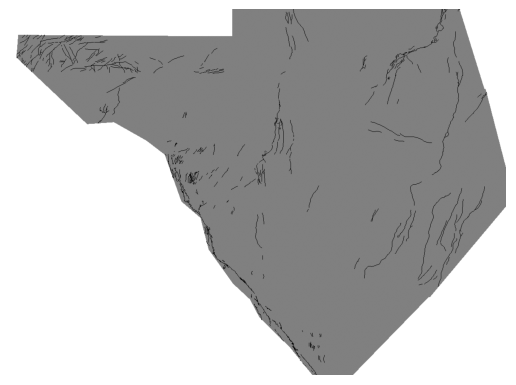

In [40]:
# compter les eléments de Y_RAW
unique, counts = np.unique(Y_RAW, return_counts=True)
for value, count in zip(unique, counts):
    print(f"Valeur {value}: {count} pixels")

#afficher la map 
zoom_coord = [(356763,4221391),(473295,4131499)] # coin en haut à gauche et coin en bas à droite
print(f"zoom_coord = {zoom_coord}")
zoom_coord = [src_y.index(x,y) for x, y in zoom_coord] # conversion en indices de tableau
print(f"zoom_coord = {zoom_coord}")
zoom_id = (slice(zoom_coord[0][0], zoom_coord[1][0]), slice(zoom_coord[0][1], zoom_coord[1][1]))
zoomed_Y_RAW = Y_RAW[zoom_id] # découpe de la zone d'intérêt
plt.imshow(zoomed_Y_RAW, cmap=ListedColormap(["gray", "black"]), vmin=0, vmax=1)
plt.axis("off")
plt.show()

In [60]:
STEP = 1
KERNEL_SIZE = 10

def dilate_faults(Y_RAW, STEP=1, KERNEL_SIZE=10):
    Y_buff = Y_RAW.copy()

    for i, j in itertools.product(range(0, H, STEP), range(0, W, STEP)):
        if np.isnan(Y_buff[i, j]):
            continue

        if Y_RAW[i, j] == 1:
            y0 = max(0, i - KERNEL_SIZE // 2)
            y1 = min(H, i + KERNEL_SIZE // 2)
            x0 = max(0, j - KERNEL_SIZE // 2)
            x1 = min(W, j + KERNEL_SIZE // 2)

            for x in range(x0, x1):
                for y in range(y0, y1):
                    if not np.isnan(Y_buff[y, x]):
                        Y_buff[y, x] = 1
    return Y_buff
Y_buff = dilate_faults(Y_RAW, STEP=STEP, KERNEL_SIZE=KERNEL_SIZE)
unique, counts = np.unique(Y_buff, return_counts=True)
for value, count in zip(unique, counts):
    print(f"Valeur {value}: {count} pixels")

Valeur 0.0: 4367971 pixels
Valeur 1.0: 799402 pixels
Valeur nan: 7111787 pixels


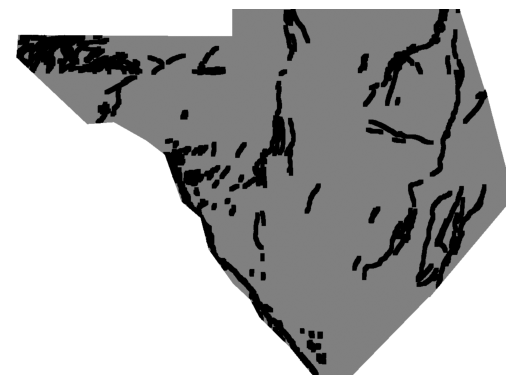

In [90]:
#afficher la map 
plt.imshow(Y_buff[zoom_id], cmap=ListedColormap(["gray", "black"]), vmin=0, vmax=1)
plt.axis("off")
plt.show()



Nombre de zones : 544
Plus grande zone : 23548
Plus petite zone : 51
Taille moyenne : 1469.4889705882354


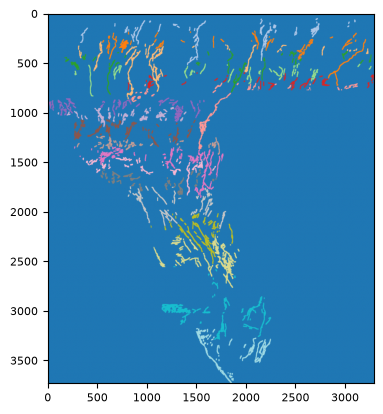

In [112]:
from scipy import ndimage as ndi
import numpy as np
import matplotlib.pyplot as plt


def set_block_labels(Y_buff):
    fault_mask = (Y_buff == 1)
    # 8 voisins : horizontal, vertical et diagonaux
    structure = np.ones((3, 3), dtype=bool)
    Y_blocks, block_count = ndi.label(fault_mask, structure=structure)
    Y_blocks = Y_blocks.astype(np.float32)
    Y_blocks[~fault_mask] = np.nan
    return Y_blocks, block_count

Y_blocks, block_count = set_block_labels(Y_buff)
print("Nombre de zones :", block_count)

unique, sizes = np.unique(Y_blocks[Y_blocks > 0], return_counts=True)

print("Plus grande zone :", sizes.max())
print("Plus petite zone :", sizes.min())
print("Taille moyenne :", sizes.mean())

# on affiche la map, la couleur de la zone est celle de la cmap en 2D
plt.imshow(Y_blocks, cmap='tab20', vmin=0, vmax=block_count)

In [102]:
N_JOBS = 24
KS_range = range(1, 100, 1)  # tailles de noyau à tester
def count_labels_for_kernel(KS):
    Y_buff_ks = dilate_faults(Y_RAW, STEP=STEP, KERNEL_SIZE=KS)
    return Y_buff_ks

all_results = Parallel(
    n_jobs=N_JOBS,
    backend="loky",
    max_nbytes="10M"
)(
    delayed(count_labels_for_kernel)(KS)
    for KS in KS_range
)



In [124]:
# on crée un gif de la croissance des buffers pour visualiser l'effet de la dilatation sur le nombre de zones
# les images a affichéss sont des plt.imshow() de Y_buff pour chaque taille de noyau, avec le titre indiquant la taille du noyau 
import imageio
images = []
for result, KS in zip(all_results, KS_range):
    plt.imshow(result, cmap=ListedColormap(["gray", "black"]), vmin=0, vmax=1)
    plt.axis("off")
    plt.title(f"Taille du noyau : {KS}")
    plt.savefig(f"notebook/figs/make_gif/dilatation_{KS}.png")
    plt.close()
    images.append(imageio.imread(f"notebook/figs/make_gif/dilatation_{KS}.png"))

imageio.mimsave(r"notebook/figs/dilatation_effect.gif", images, duration=0.5)


C:\Users\Nicolas\AppData\Local\Temp\ipykernel_6396\25534971.py:11: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  images.append(imageio.imread(f"notebook/figs/make_gif/dilatation_{KS}.png"))


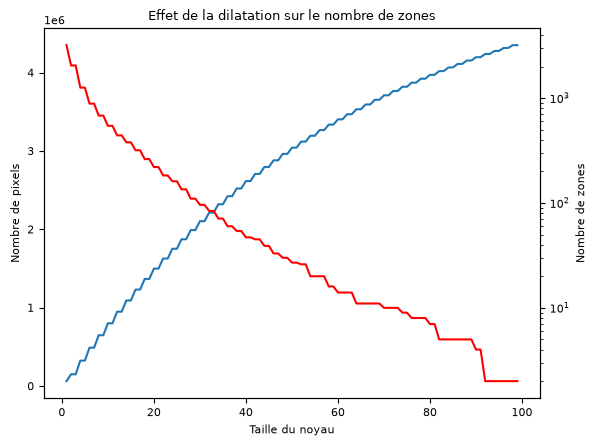

<Figure size 640x480 with 0 Axes>

In [ ]:
# premier axe avec lke nomnre de pixels considérés comme contenant de l'information pour une faille (1)
plt.plot(KS_range, [np.count_nonzero(result == 1) for result in all_results])
plt.xlabel("Taille du noyau")
plt.ylabel("Nombre de pixels")
plt.yscale("log")
#sur un autre axe Y on peut afficher le nombre de zones
plt.twinx()
plt.plot(KS_range, [set_block_labels(result)[1] for result in all_results], color='red')
plt.xlabel("Taille du noyau")
plt.ylabel("Nombre de zones")
plt.title("Effet de la dilatation sur le nombre de zones")

plt.show()
plt.savefig(r"notebook\figs\dilatation_effect.png")

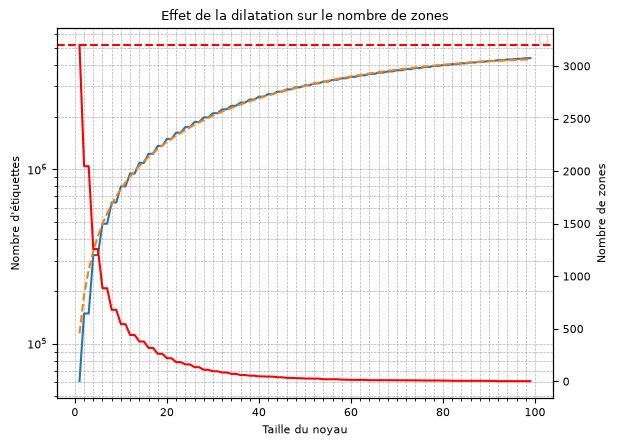

In [130]:
#fit [KS_range, nb_etiquettes] sous la forme de ax² + bx + c = y
coefficients = np.polyfit(KS_range, nb_etiquettes, 2)
plt.plot(KS_range, nb_etiquettes, label="Données")
plt.plot(KS_range, np.polyval(coefficients, KS_range), label=f"Ajustement quadratique: {coefficients[0]:.2f}x² + {coefficients[1]:.2f}x + {coefficients[2]:.2f}", linestyle="--")
plt.xlabel("Taille du noyau") 
plt.ylabel("Nombre d'étiquettes")#Y va de 60 000 à 4e6
plt.xticks(range(0, 100, 2), minor=True)
plt.yticks(np.arange(0, 4.5e6, 0.5e5), minor=True)
plt.grid(which="both", linestyle="--", linewidth=0.5)
#mettr eune ligne horizontale à 799402+4367971 
plt.axhline(y=799402+4367971, color="red", linestyle="--", label="Nombre de pixels valides")
#logscale pour l'axe des y
plt.yscale("log")
#sur un autre axe Y on peut afficher le nombre de zones
plt.twinx()
plt.plot(KS_range, [set_block_labels(result)[1] for result in all_results], color='red')
plt.xlabel("Taille du noyau")
plt.ylabel("Nombre de zones")
plt.title("Effet de la dilatation sur le nombre de zones")
plt.legend()
plt.savefig(r"notebook\figs\dilatation_effect_with_fit.png")

10 semble d'être une bonne option de kernel size, il faut repondre a la question si cette taille repond a la question du compris de la grandeur pour pouvoir capter de l'information et assez petit pour que cette information apartienne bien a la faille du milieu et non à une autre faille qui ne serrait pas repertorié.

In [136]:
KERNEL_SIZE = 10
Y_buff = dilate_faults(Y_RAW, STEP=1, KERNEL_SIZE=KERNEL_SIZE)
MASK = (Y_buff == 1)
Y_blocks, block_count = set_block_labels(Y_buff)
Y_blocks = Y_blocks.astype(np.float32)
Y_blocks[~MASK] = np.nan  # on ne garde que les zones dilatées
plt.imshow(Y_blocks, cmap='tab20', vmin=0, vmax=block_count)
print("Nombre de zones :", block_count)

ValueError: cannot convert float NaN to integer

Zones agregees: 544
ARI consensus/spectral direct: 0.325
Silhouette consensus: 0.013
Silhouette spectral direct: 0.109

 kmeans_consensus
fold 0: 125 zones, 166956 pixels
fold 1: 107 zones, 146126 pixels
fold 2: 85 zones, 191343 pixels
fold 3: 114 zones, 89996 pixels
fold 4: 113 zones, 204981 pixels

 spectral_direct
fold 0: 59 zones, 103114 pixels
fold 1: 88 zones, 79866 pixels
fold 2: 96 zones, 187204 pixels
fold 3: 148 zones, 172875 pixels
fold 4: 153 zones, 256343 pixels


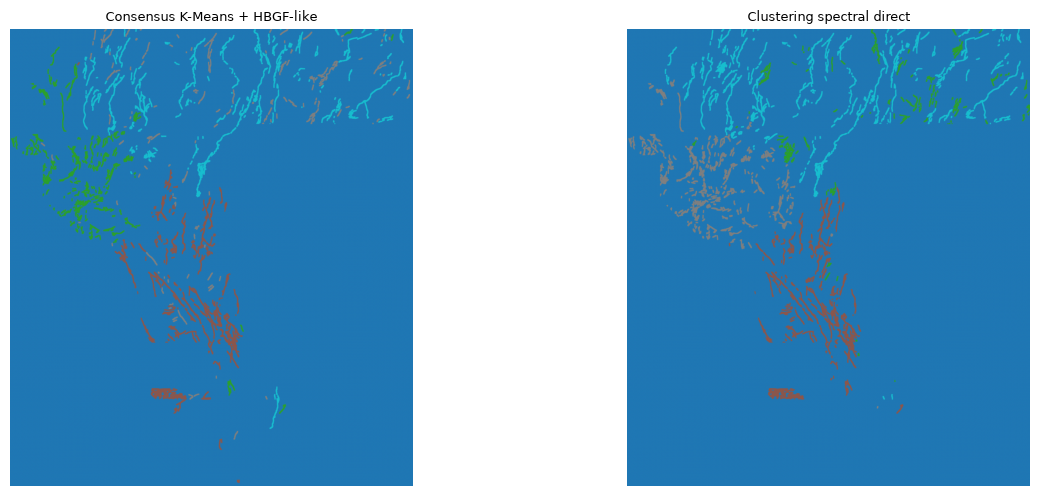

Variables creees: block_df, fold_map_consensus, fold_map_spectral,
cv_splits_consensus, cv_splits_spectral


In [134]:
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score, adjusted_rand_score

N_FOLDS = 5
if block_count < N_FOLDS:
    raise ValueError(f"{block_count} zones disponibles pour {N_FOLDS} folds")

rows = []
for block_id in range(1, block_count + 1):
    rr, cc = np.where(Y_blocks == block_id)
    if rr.size == 0:
        continue

    x_mean, y_mean = src_x.xy(rr.mean(), cc.mean())
    cov_mean = np.nanmean(X[:, rr, cc], axis=1)
    observed = Y_RAW[rr, cc]
    observed = observed[~np.isnan(observed)]
    target_mean = np.mean(observed) if observed.size else np.nan
    rows.append({"block_id": block_id, "x": x_mean, "y": y_mean,
                 "target_mean": target_mean, "pixel_count": int(rr.size),
                 "covariates": cov_mean})

block_df = pd.DataFrame(rows)
covariates = np.vstack(block_df["covariates"].to_numpy())
location = block_df[["x", "y"]].to_numpy()
target = block_df[["target_mean"]].to_numpy()

def impute_scale(values):
    values = SimpleImputer(strategy="median").fit_transform(values)
    return StandardScaler().fit_transform(values)

loc_z = impute_scale(location)
cov_z = impute_scale(covariates)
target_z = impute_scale(target)

cluster_location = KMeans(n_clusters=N_FOLDS, n_init=20, random_state=SEED).fit_predict(loc_z)
cluster_covariates = KMeans(n_clusters=N_FOLDS, n_init=20, random_state=SEED).fit_predict(cov_z)
cluster_target = KMeans(n_clusters=N_FOLDS, n_init=20, random_state=SEED).fit_predict(target_z)

n_blocks = len(block_df)
affinity_consensus = np.zeros((n_blocks, n_blocks), dtype=float)
for partition in (cluster_location, cluster_covariates, cluster_target):
    affinity_consensus += (partition[:, None] == partition[None, :]) / 3.0
np.fill_diagonal(affinity_consensus, 1.0)

fold_kmeans_consensus = SpectralClustering(
    n_clusters=N_FOLDS, affinity="precomputed",
    assign_labels="cluster_qr", random_state=SEED,
).fit_predict(affinity_consensus)

combined_z = np.column_stack((loc_z, cov_z, target_z))
fold_spectral_direct = SpectralClustering(
    n_clusters=N_FOLDS, affinity="nearest_neighbors",
    n_neighbors=min(15, n_blocks - 1),
    assign_labels="cluster_qr", random_state=SEED,
).fit_predict(combined_z)

print("Zones agregees:", n_blocks)
print("ARI consensus/spectral direct:", round(adjusted_rand_score(fold_kmeans_consensus, fold_spectral_direct), 3))
print("Silhouette consensus:", round(silhouette_score(loc_z, fold_kmeans_consensus), 3))
print("Silhouette spectral direct:", round(silhouette_score(combined_z, fold_spectral_direct), 3))

for method, fold_labels in (("kmeans_consensus", fold_kmeans_consensus),
                            ("spectral_direct", fold_spectral_direct)):
    print("\n", method)
    for fold_id in range(N_FOLDS):
        ids = np.flatnonzero(fold_labels == fold_id)
        pixels = int(block_df.iloc[ids]["pixel_count"].sum())
        print(f"fold {fold_id}: {len(ids)} zones, {pixels} pixels")

fold_map_consensus = np.full((H, W), np.nan, dtype=np.float32)
fold_map_spectral = np.full((H, W), np.nan, dtype=np.float32)
for pos, row in block_df.iterrows():
    block_id = int(row["block_id"])
    mask = Y_blocks == block_id
    fold_map_consensus[mask] = fold_kmeans_consensus[pos]
    fold_map_spectral[mask] = fold_spectral_direct[pos]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, fold_map, title in (
    (axes[0], fold_map_consensus, "Consensus K-Means + HBGF-like"),
    (axes[1], fold_map_spectral, "Clustering spectral direct"),
):
    ax.imshow(fold_map, cmap="tab10", vmin=0, vmax=N_FOLDS - 1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

cv_splits_consensus = []
cv_splits_spectral = []
for fold_id in range(N_FOLDS):
    cv_splits_consensus.append((
        block_df.index[fold_kmeans_consensus != fold_id].to_numpy(),
        block_df.index[fold_kmeans_consensus == fold_id].to_numpy(),
    ))
    cv_splits_spectral.append((
        block_df.index[fold_spectral_direct != fold_id].to_numpy(),
        block_df.index[fold_spectral_direct == fold_id].to_numpy(),
    ))

print("Variables creees: block_df, fold_map_consensus, fold_map_spectral,")
print("cv_splits_consensus, cv_splits_spectral")